# Seeing Red (Templar)

Seeing Red is a rage buff. For a skill-scaled duration the Templar's **weapon value** rises by
three times its current value (at most +127), and new crowd-control debuffs refuse to attach.
It costs 75 endurance and has a 60 s cooldown.

| | |
|---|---|
| Class | Templar |
| Target | Self only |
| Cost | 75 endurance, spent before `add_spell` (a refused attach keeps the cost and starts no cooldown) |
| Cooldown | 60 s (separate `SK_SEEING_RED` marker) |
| Landing roll | none |
| Duration | $15 + \operatorname{clamp}(\lfloor p/5\rfloor, 0, 75)$ s |
| Effect | `weapon[1] += clamp(3·weapon, 3, 127)`; `add_spell` refuses `SK_STUN`, `SK_WARCRY2`, `SK_CURSE`, `SK_CONTAGION`, `SK_GUNPOWDER_FLASH`, `SK_DISARM` while the buff is up |
| Source | `server/src/driver/skill/templar.rs::skill_seeing_red`; block in `driver/skill/common.rs::add_spell` |

---

# Formula

With $W$ the caster's **current** weapon value (`ch.weapon`, which already includes other buffs
such as Sun's Blessing) and $p$ the raw modified skill:

$$
\text{bonus} = \operatorname{clamp}(3W,\ 3,\ 127)
\qquad
W_\text{rage} = \min(250,\ W + \text{bonus})
$$

$$
\text{duration} = 15 + \operatorname{clamp}\!\left(\lfloor p/5 \rfloor,\ 0,\ 75\right)\ \text{s}
\qquad
\text{uptime} = \min\!\left(1,\ \frac{\text{duration}}{60}\right)
$$

The skill only sets the duration. The size of the bonus depends on the weapon alone, so it is
the same at skill 1 and skill 200.

| Quantity | Breakpoint |
|---|---|
| Bonus cap | +127 at $W \ge 43$ (i8 limit) |
| Duration at the raise caps | 36 s at 105, 39 s at 120 |
| Duration ceiling | 90 s at $p \ge 375$; 100% uptime from $p \ge 225$ |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
COOLDOWN_S = 60
END_COST = 75
BLOCKED = ("SK_STUN", "SK_WARCRY2", "SK_CURSE", "SK_CONTAGION", "SK_GUNPOWDER_FLASH", "SK_DISARM")

# Model

In [2]:
def rage_bonus(weapon):
    return mm.clamp(np.asarray(weapon) * 3, 3, 127)


def rage_duration_s(p):
    return 15 + mm.clamp(mm.idiv(p, 5), 0, 75)


def uptime(p):
    return np.minimum(1.0, np.asarray(rage_duration_s(p)) / COOLDOWN_S)


def hit_multiplier(weapon, strength=80, armor=20):
    """Damage per landed hit with Seeing Red / without it (normal hits, Δ = 0).

    NaN when the unbuffed weapon cannot get through the armor at all."""
    raged = min(250, weapon + rage_bonus(weapon))
    base = mm.melee_hit_hp(weapon, strength, armor)
    return mm.melee_hit_hp(raged, strength, armor) / base if base > 0 else np.nan


def cycle_gain(p, weapon, strength=80, armor=20):
    """Average melee damage multiplier over a 60 s cooldown cycle, recasting on cooldown."""
    return 1 + uptime(p) * (hit_multiplier(weapon, strength, armor) - 1)

# Validation

- `seeing_red_spends_endurance_and_starts_cooldown`: skill 50, weapon 10 → `a_end` 100,000 →
  25,000. `weapon[1] == 30`, the buff lasts `TICKS*25` and the cooldown `TICKS*60` on a separate
  item. A second cast during the cooldown spends nothing.
- `endurance_skills_do_nothing_without_enough_endurance`: 74,000 endurance is refused.
- `seeing_red_blocks_only_crowd_control_temps`: the six temps above are blocked;
  `SK_WARCRY` (the −15 attribute debuff), `SK_BLESS` and the Seeing Red items are not.

In [3]:
assert 100_000 - END_COST * 1000 == 25_000 and 74_000 < END_COST * 1000
assert rage_bonus(10) == 30 and rage_duration_s(50) == 25
assert mm.TICKS * rage_duration_s(50) == mm.TICKS * 25 and mm.TICKS * COOLDOWN_S == 2160
assert rage_bonus(42) == 126 and rage_bonus(43) == 127 and rage_bonus(0) == 3
assert rage_duration_s(105) == 36 and rage_duration_s(120) == 39 and rage_duration_s(225) == 60
print("Seeing Red model OK")

Seeing Red model OK


# Plots

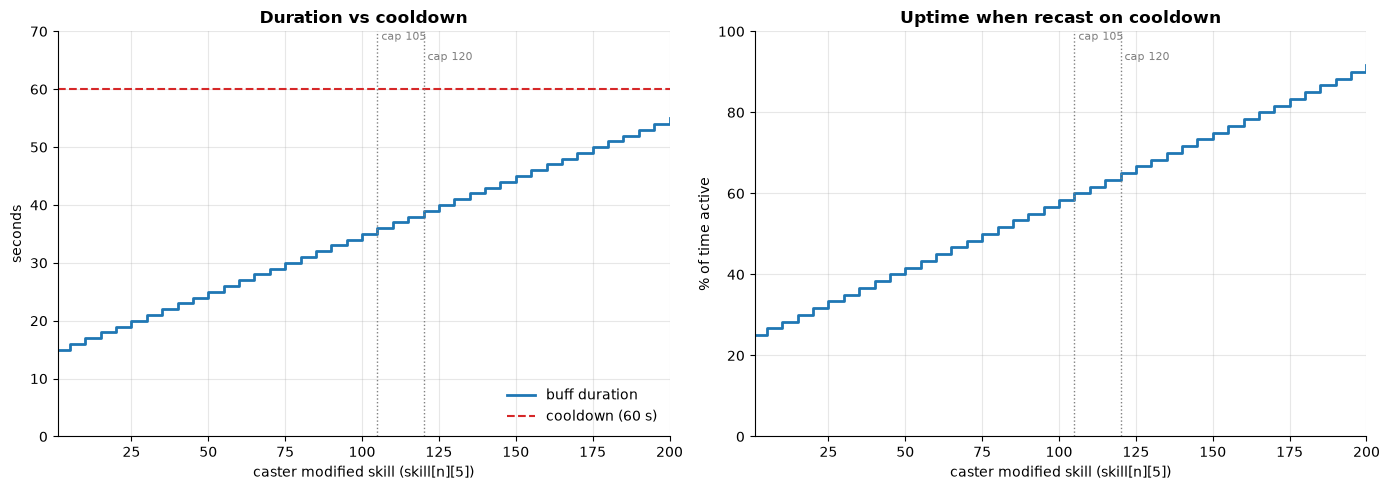

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.step(P, rage_duration_s(P), where="post", label="buff duration")
ax.axhline(COOLDOWN_S, color="tab:red", ls="--", lw=1.5, label="cooldown (60 s)")
mm.skill_axis(ax, "seconds", "Duration vs cooldown")
ax.set_ylim(0, 70)
mm.mark_caps(ax)
ax.legend(loc="lower right")

ax = axes[1]
ax.step(P, 100 * uptime(P), where="post")
mm.skill_axis(ax, "% of time active", "Uptime when recast on cooldown")
ax.set_ylim(0, 100)
mm.mark_caps(ax)
plt.tight_layout()

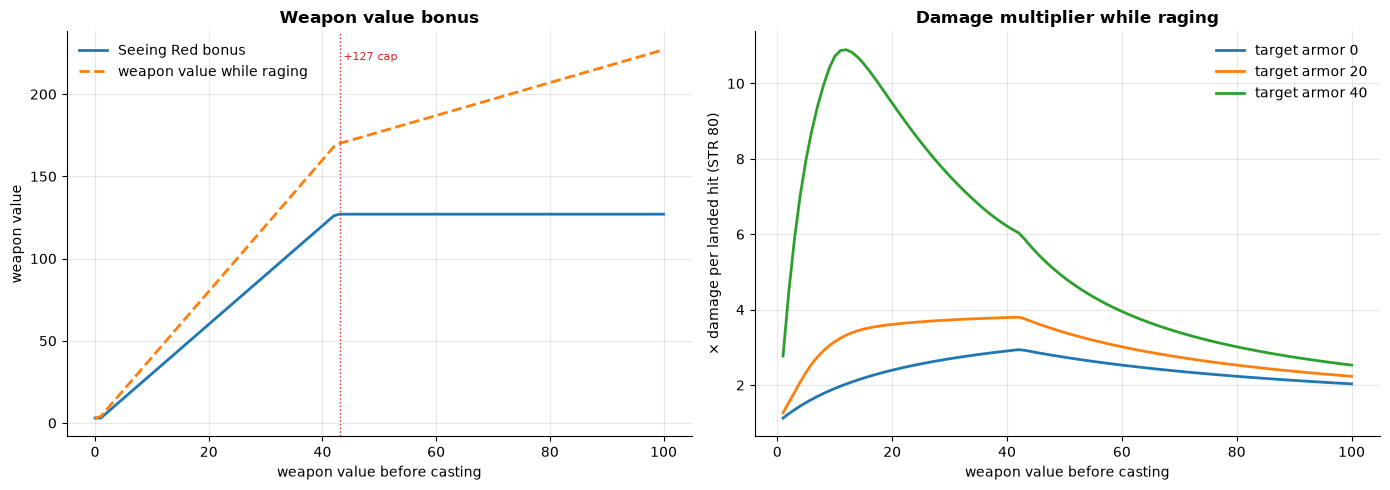

In [5]:
# The bonus depends on weapon value only, so these use weapon value on the x-axis.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
W = np.arange(0, 101)

ax = axes[0]
ax.plot(W, rage_bonus(W), label="Seeing Red bonus")
ax.plot(W, W + rage_bonus(W), ls="--", label="weapon value while raging")
ax.axvline(43, color="tab:red", ls=":", lw=1)
ax.text(43, 0.95, " +127 cap", transform=ax.get_xaxis_transform(), fontsize=8, color="tab:red", va="top")
ax.set_xlabel("weapon value before casting")
ax.set_ylabel("weapon value")
ax.set_title("Weapon value bonus")
ax.legend()

ax = axes[1]
for armor in (0, 20, 40):
    ax.plot(W[1:], [hit_multiplier(int(w), armor=armor) for w in W[1:]], label=f"target armor {armor}")
ax.set_xlabel("weapon value before casting")
ax.set_ylabel("× damage per landed hit (STR 80)")
ax.set_title("Damage multiplier while raging")
ax.legend()
plt.tight_layout()

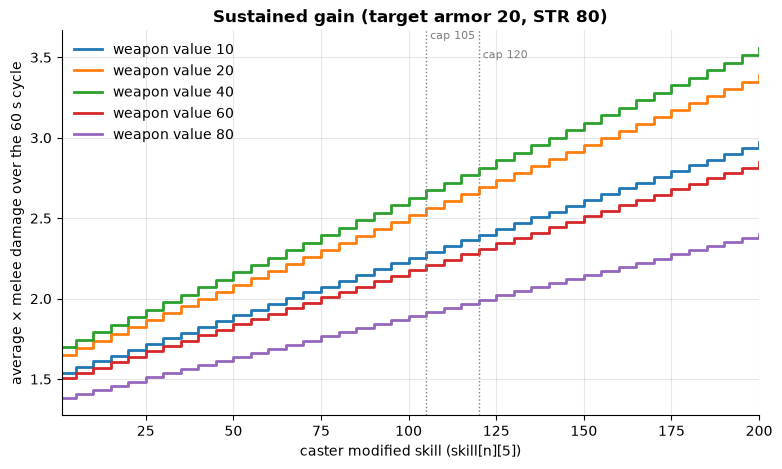

In [6]:
fig, ax = plt.subplots()
for wv in mm.WV_SWEEP:
    ax.step(P, cycle_gain(P, wv), where="post", label=f"weapon value {wv}")
mm.skill_axis(ax, "average × melee damage over the 60 s cycle", "Sustained gain (target armor 20, STR 80)")
mm.mark_caps(ax)
ax.legend()

# Observations

- **A huge damage buff whose size ignores the skill.** The bonus is 3× the current weapon value,
  so a WV-40 Templar swings at WV 160. Against armor 20 with STR 80 a landed hit goes from 10.75 to
  40.75 HP (×3.8); against armor 0, from 15.75 to 45.75 (×2.9). The multiplier peaks at WV 42,
  the last value before the +127 cap. Against heavy armor, low weapon values gain far more (×10.9
  at WV 12 against armor 40), because the bonus lifts rolls that armor used to swallow entirely.
- **The skill only buys uptime.** Duration is 36 s at 105 and 39 s at 120, so the buff is up 60% /
  65% of a 60 s cycle. Recast on cooldown, a WV-40 Templar averages ×2.7 (skill 105) to ×2.8
  (skill 120) melee damage against armor 20 for 75 endurance a minute.
- **It multiplies other weapon buffs.** The bonus is taken from `ch.weapon`, which already includes
  Sun's Blessing. At skill 105 Sun's Blessing lifts WV 40 to 76 and STR to 116; Seeing Red then
  adds the full +127 (WV 203). A landed hit against armor 20 goes from 10.75 to 53.75 HP (×5.0),
  ×2.4 on top of Sun's Blessing alone.
- **The crowd-control immunity is narrow but useful.** Only six temps are refused: Stun, War-Stun,
  Curse, Contagion, Gunpowder Flash's slow and Disarm. Existing debuffs are not removed, and
  Warcry's −15 attribute debuff (`SK_WARCRY`) still lands even when its stun is refused.
- **Failure modes.** Endurance is spent before `add_spell`, so a refused attach (NoMagic tile,
  full spell slots) costs 75 endurance and starts no cooldown.
- **The doc comment is stale.** It describes "a large temporary weapon-skill bonus", but the item
  sets `weapon[1]` (weapon value). Weapon Skill is untouched.
- **Balance suggestions.** Use a percentage of weapon value that grows with skill (for example
  `weapon * p / 200`, +21 at WV 40 and skill 105) with a lower cap (around +40), so the skill
  matters and stacking with Sun's Blessing stays bounded.